In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Libraries imported successfully!


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving dataset.csv to dataset.csv


In [ ]:

import io

filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (22000, 2)

Column names:
['Text', 'language']

First five rows:


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch



Missing values:
Text        0
language    0
dtype: int64


In [ ]:

TEXT_COLUMN = "Text"
LANGUAGE_COLUMN = "language"

df = df[[TEXT_COLUMN, LANGUAGE_COLUMN]].copy()

df = df.dropna(subset=[TEXT_COLUMN, LANGUAGE_COLUMN])

df[TEXT_COLUMN] = df[TEXT_COLUMN].astype(str).str.strip()
df[LANGUAGE_COLUMN] = df[LANGUAGE_COLUMN].astype(str).str.strip()

df = df[
    (df[TEXT_COLUMN] != "") &
    (df[LANGUAGE_COLUMN] != "")
]

df = df.drop_duplicates()

print("Cleaned dataset shape:", df.shape)
print("\nNumber of languages:", df[LANGUAGE_COLUMN].nunique())
print("\nLanguage distribution:")
print(df[LANGUAGE_COLUMN].value_counts())


Cleaned dataset shape: (21858, 2)

Number of languages: 22

Language distribution:
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


In [ ]:

df = (
    df.groupby("language", group_keys=False)
      .apply(lambda x: x.sample(
          n=min(len(x), 2000),
          random_state=42
      ))
      .reset_index(drop=True)
)

print("Dataset shape:", df.shape)
print("Number of languages:", df["language"].nunique())
display(df.head())


Dataset shape: (21858, 2)
Number of languages: 22


/tmp/ipykernel_2241/3660138934.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(


,Text,language
0,ولكن سيمور قامت بسحب قصتها لاحقا وتقدم رجل اخر...,Arabic
1,استمرت هذه الابادة حتى أنهاها القائمون على خدم...,Arabic
2,حمض البورونيك هو حمض مشتق من حمض البوريك وذلك ...,Arabic
3,"قاموس ميريام وبستر إما الشيء الذي هو ""من أو ال...",Arabic
4,وخلافا لتقارير الإعلام والجدال في ذلك الوقت ال...,Arabic


In [ ]:

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(df["language"])

texts = df["Text"].tolist()
labels = df["label"].values

num_classes = len(label_encoder.classes_)

print("Number of languages:", num_classes)
print("Languages:", label_encoder.classes_)
print("Text samples:", len(texts))
print("Labels shape:", labels.shape)


Number of languages: 22
Languages: ['Arabic' 'Chinese' 'Dutch' 'English' 'Estonian' 'French' 'Hindi'
 'Indonesian' 'Japanese' 'Korean' 'Latin' 'Persian' 'Portugese' 'Pushto'
 'Romanian' 'Russian' 'Spanish' 'Swedish' 'Tamil' 'Thai' 'Turkish' 'Urdu']
Text samples: 21858
Labels shape: (21858,)


In [ ]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(texts)

sequences = tokenizer.texts_to_sequences(texts)

X = pad_sequences(
    sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Vocabulary size:", min(len(tokenizer.word_index) + 1, MAX_WORDS))
print("Input shape:", X.shape)
print("Labels shape:", labels.shape)
print("\nFirst numerical sequence:")
print(X[0])


Vocabulary size: 20000
Input shape: (21858, 100)
Labels shape: (21858,)

First numerical sequence:
[ 2152  7443  3874     1     1     1     1 11860 10793     1  4399     1
     1 16581 16582  8557   456     1 11861     1 16583    19   632    34
 18964     1     1     1 16584  7444    34     1 10794 18965     1   112
     1  2153  7963    19   456     1  3744  2766    34   433  1892    34
     1     1 16585  7445   455  8558  1621     1     1  2049    19  1119
   696   412 18964     1     1 14654    19  3465  1180   212 14655  1119
     1     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0]


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training samples: 17486
Testing samples: 4372
Training labels: (17486,)
Testing labels: (4372,)


In [ ]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=64),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.build(input_shape=(None, MAX_LEN))

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 22)             │           726 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,315,830 (5.02 MB)

 Trainable params: 1,315,830 (5.02 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

print("Model training completed!")


Epoch 1/5
246/246 ━━━━━━━━━━━━━━━━━━━━ 27s 92ms/step - accuracy: 0.0886 - loss: 2.9438 - val_accuracy: 0.1218 - val_loss: 2.7227
Epoch 2/5
246/246 ━━━━━━━━━━━━━━━━━━━━ 23s 92ms/step - accuracy: 0.1376 - loss: 2.5799 - val_accuracy: 0.1921 - val_loss: 2.4763
Epoch 3/5
246/246 ━━━━━━━━━━━━━━━━━━━━ 42s 96ms/step - accuracy: 0.0995 - loss: 2.7927 - val_accuracy: 0.1132 - val_loss: 2.6923
Epoch 4/5
246/246 ━━━━━━━━━━━━━━━━━━━━ 39s 90ms/step - accuracy: 0.1320 - loss: 2.5415 - val_accuracy: 0.1407 - val_loss: 2.3604
Epoch 5/5
246/246 ━━━━━━━━━━━━━━━━━━━━ 23s 94ms/step - accuracy: 0.1402 - loss: 2.3745 - val_accuracy: 0.1372 - val_loss: 2.4587
Model training completed!


In [ ]:

import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted", zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, average="weighted", zero_division=0))
print("F1-Score :", f1_score(y_test, y_pred, average="weighted", zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))


137/137 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step
Accuracy : 0.13655077767612075
Precision: 0.14438380219430008
Recall   : 0.13655077767612075
F1-Score : 0.06853665912103336

Classification Report:
              precision    recall  f1-score   support

      Arabic       0.00      0.00      0.00       200
     Chinese       0.00      0.00      0.00       200
       Dutch       0.00      0.00      0.00       199
     English       0.00      0.00      0.00       200
    Estonian       0.08      0.05      0.06       200
      French       0.00      0.00      0.00       198
       Hindi       0.45      0.46      0.46       198
  Indonesian       0.29      0.54      0.38       195
    Japanese       0.00      0.00      0.00       200
      Korean       0.00      0.00      0.00       200
       Latin       0.00      0.00      0.00       191
     Persian       1.00      0.05      0.10       200
   Portugese       0.00      0.00      0.00       199
      Pushto       0.22      0.91      0.36       199

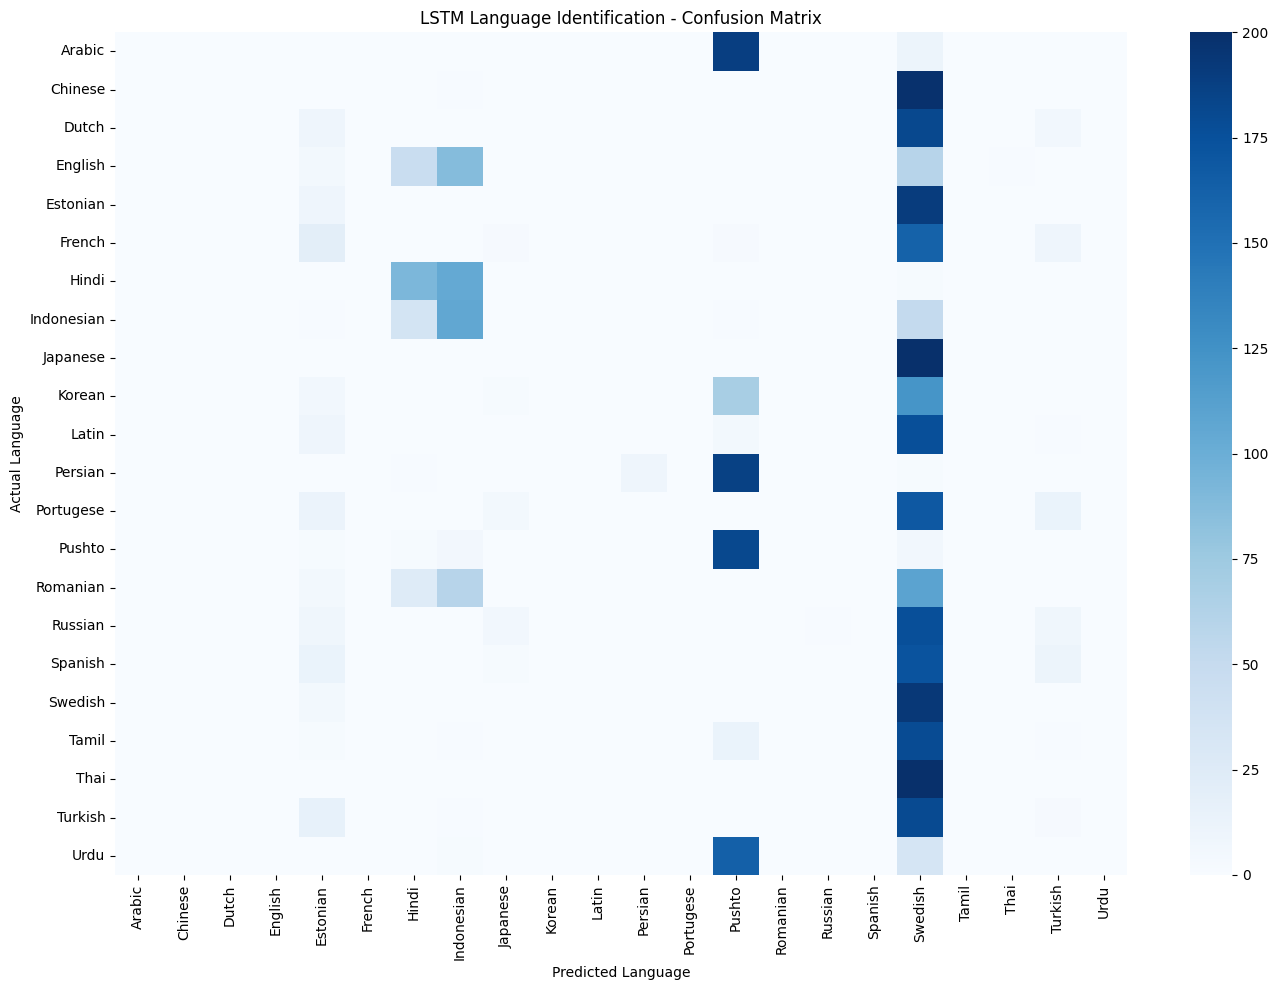

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.title("LSTM Language Identification - Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

unseen_texts = [
    "Hello, how are you today?",
    "Bonjour, comment allez-vous?",
    "Hola, ¿cómo estás?",
    "Guten Tag, wie geht es Ihnen?",
    "வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?"
]

sequences = tokenizer.texts_to_sequences(unseen_texts)

padded_sequences = pad_sequences(
    sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

predictions = model.predict(padded_sequences)
predicted_labels = np.argmax(predictions, axis=1)

for text, label, probabilities in zip(
    unseen_texts, predicted_labels, predictions
):
    language = label_encoder.inverse_transform([label])[0]
    confidence = np.max(probabilities) * 100

    print("Input text:", text)
    print("Predicted language:", language)
    print("Confidence:", round(confidence, 2), "%")
    print("-" * 40)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
Input text: Hello, how are you today?
Predicted language: Swedish
Confidence: 7.51 %
----------------------------------------
Input text: Bonjour, comment allez-vous?
Predicted language: Swedish
Confidence: 7.51 %
----------------------------------------
Input text: Hola, ¿cómo estás?
Predicted language: Swedish
Confidence: 7.51 %
----------------------------------------
Input text: Guten Tag, wie geht es Ihnen?
Predicted language: Swedish
Confidence: 7.51 %
----------------------------------------
Input text: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Predicted language: Swedish
Confidence: 7.51 %
----------------------------------------
